In [234]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from load_data import load_bmerawdata, log_vapor_pressure, pivot_bmedata

# load data
nut_df = pd.read_csv('NRC_BME690/bme_690_all_nuts.csv')
spice_df = pd.read_csv('NRC_BME690/bme_690_all_spices.csv')
herb_df = pd.read_csv('NRC_BME690/bme_690_all_herbs.csv')

# raw_df = load_bmerawdata(f'NRC_BME690/bme_690_data_14.bmerawdata')
# raw_df['source_file'] = 'raw'
# raw_df = raw_df[raw_df['timestamp_since_poweron'].between(0.2E6, 1.6E6)]
sensor_df = pd.concat([nut_df, spice_df, herb_df], ignore_index=True)

sensor_df['label_merged'] = sensor_df['label'].str.rstrip('0123456789') # merge labels like peanuts2 -> peanuts
sensor_df['log_vapor_pressure'] = log_vapor_pressure(sensor_df['temperature'], sensor_df['relative_humidity'])
sensor_df['log_resistance'] = np.log10(sensor_df['resistance_gassensor'] + 1)  # Add 1 to avoid log(0)
sensor_df.head()
    

,sensor_index,sensor_id,timestamp_since_poweron,real_time_clock,temperature,pressure,relative_humidity,resistance_gassensor,heater_profile_step_index,scanning_enabled,scanning_cycle_index,label_tag,error_code,label,class,source_file,label_merged,log_vapor_pressure,log_resistance
0,1,880502628,664224,0,36.709148,1021.732239,27.176279,262093.671875,6,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,Pecans,1.250801,5.418458
1,0,880490094,664244,0,36.242775,1021.761719,27.640745,90459.367188,7,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,Pecans,1.247255,4.956458
2,3,880492645,664370,0,36.640404,1021.617310,28.554050,96731.531250,8,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,Pecans,1.269552,4.985573
3,6,880494957,664802,0,35.828842,1021.619568,28.506971,137044.968750,8,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,Pecans,1.250560,5.136866
4,0,880490094,664944,0,36.335953,1021.758911,27.802603,106711.132812,8,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,Pecans,1.251747,5.028214


In [235]:
from sklearn.linear_model import LinearRegression, HuberRegressor, TheilSenRegressor

def normalize_by_group_wide(df):
    def get_residuals(sensor_group):
        group = sensor_group.copy()
    
        resistance_cols = [c for c in group.columns if c.startswith('log_resistance')]
        steps = [c.split('_')[-1] for c in resistance_cols]

        for step in steps:
            x = group[f'log_vapor_pressure_{step}'].to_numpy().reshape(-1,1)
            y = group[f'log_resistance_{step}']

            lr = LinearRegression()
            lr.fit(x, y)
            # retval = (y - np.mean(y)) / np.std(y, ddof=0)
            retval = y - lr.predict(x)

            group[f'resistance_compensated_{step}'] = retval

        return group

    return df.groupby('sensor_index').apply(get_residuals, include_groups=False).reset_index(level='sensor_index')
    
    
def normalize_by_group(df):
    def get_residuals(group):

        # Simpler version: subtract mean, ignore vapor pressure 
        # y = group['log_resistance']
        # return y - np.mean(y)

        # We need at least 2 points to fit a line; otherwise, return 0 (centered)
        if len(group) < 2:
            return pd.Series(0, index=group.index)

        X = group['log_vapor_pressure'].to_numpy().reshape(-1, 1)
        y = group['log_resistance'].to_numpy().reshape(-1,)

        lr = LinearRegression()
        # lr = TheilSenRegressor()
        # lr = HuberRegressor()
        lr.fit(X, y)
        retval = y - lr.predict(X)

        # retval = (y - np.mean(y)) / np.std(y, ddof=0)
        return pd.Series(retval.flatten(), index=group.index)

    # Group by sensor and step to isolate specific heater behaviors
    # This automatically handles the 4 different profiles across the 8 sensors
    # Since response to envionmental conditions (temperature, humidity) depends on sensor temperature,
    # remove the baseline response for each step to help generalize across sensors
    return df.groupby(['sensor_index', 'heater_profile_step_index'], 
                                     group_keys=False).apply(get_residuals, include_groups=False)
    # Simpler: Group by sensor only, average across all heater steps
    # return df.groupby(['sensor_index'], 
    #                                 group_keys=False).apply(get_residuals, include_groups=False)



# sensor_df['resistance_compensated'] = normalize_by_group(sensor_df)
# feature_matrix = pivot_bmedata(sensor_df, features=['log_resistance', 'relative_humidity', 'temperature', 'log_vapor_pressure', 'resistance_compensated'])
feature_matrix = pivot_bmedata(sensor_df, features=['log_resistance', 'relative_humidity', 'temperature', 'log_vapor_pressure', 'resistance_gassensor'])
feature_matrix = normalize_by_group_wide(feature_matrix)
feature_matrix.head()

,sensor_index,source_file,cycle_id,label_merged,label_tag,label,class,log_resistance_0,log_resistance_1,log_resistance_2,...,resistance_compensated_0,resistance_compensated_1,resistance_compensated_2,resistance_compensated_3,resistance_compensated_4,resistance_compensated_5,resistance_compensated_6,resistance_compensated_7,resistance_compensated_8,resistance_compensated_9
1,0,bme_690_data_11.csv,1,Pecans,1,Pecans,nuts,5.083447,7.104251,7.021992,...,0.099642,0.222993,0.222782,0.197631,0.146054,0.145019,0.145468,0.081088,0.072866,0.062000
2,0,bme_690_data_11.csv,2,Pecans,1,Pecans,nuts,5.107865,7.148094,7.061368,...,0.056457,0.140721,0.148419,0.172527,0.119770,0.115049,0.112814,0.069866,0.061939,0.051044
3,0,bme_690_data_11.csv,3,Pecans,1,Pecans,nuts,5.120106,7.172830,7.090813,...,0.046804,0.126635,0.137597,0.152798,0.102903,0.100341,0.096622,0.063970,0.058560,0.046107
4,0,bme_690_data_11.csv,4,Pecans,1,Pecans,nuts,5.127210,7.181499,7.096486,...,0.041595,0.114056,0.120639,0.128665,0.085196,0.079769,0.080624,0.059422,0.052587,0.044201
5,0,bme_690_data_11.csv,5,Pecans,1,Pecans,nuts,5.118097,7.165202,7.076749,...,0.022547,0.080327,0.082723,0.099025,0.062884,0.061411,0.060470,0.050337,0.045653,0.038121


In [236]:
# print(sensor_df.groupby(['sensor_index', 'heater_profile_step_index'], group_keys=False)['resistance_compensated'].mean())
# cols = [c for c in feature_matrix.columns if c.startswith('resistance_compensated')]
# subset = feature_matrix[feature_matrix['sensor_index'] == 0]
# print(f"{len(subset)=}: {subset[cols].mean()}")

In [237]:
def row_wise_delta(df, feature_prefix='log_resistance'):
    # Identify the columns that make up the feature vector
    # (Excluding metadata like sensor_index, cycle_id, and label)
    feature_cols = [c for c in df.columns if feature_prefix in c]
    
    # Extract the data as a matrix
    X = df[feature_cols].values
    
    # Calculate first difference for each row, "first difference instance normalization"
    row_diff = np.diff(X, axis=1)
    # Prepend a column of zeros to maintain the same shape (or you could choose to drop the first column)
    row_diff = np.hstack([np.zeros((row_diff.shape[0], 1)), row_diff])

    # take delta relative to first column, "first sample instance normalization"
    # row_diff = X - X[:, 0, None]
    
    # Add new difference columns to the existing dataframe
    for col_idx, col_name in enumerate(feature_cols):
        diff_col_name = f"diff_{col_name}"
        
        df[diff_col_name] = row_diff[:, col_idx]
    
    return df

# Usage
feature_matrix = row_wise_delta(feature_matrix, feature_prefix='log_resistance')
feature_matrix = row_wise_delta(feature_matrix, feature_prefix='resistance_compensated')
feature_matrix = row_wise_delta(feature_matrix, feature_prefix='resistance_gassensor')

In [ ]:
# Configuration: Choose your sensor K (0, 1, 2, or 3)
# Heater profiles = [354, 501, 411, 301]
K = 1
PAIR_K = K + 4

# FEATURE_LABEL is what is used for classification later on.
# FEATURE_LABEL = 'resistance_gassensor'
FEATURE_LABEL = 'log_resistance' 
# FEATURE_LABEL = 'resistance_compensated'
# FEATURE_LABEL = 'diff_log_resistance' 
# FEATURE_LABEL = 'diff_resistance_compensated'
LABEL = 'Chestnuts'

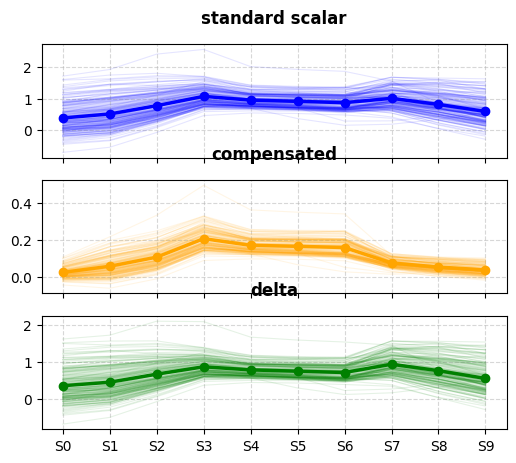

In [297]:
from sklearn.preprocessing import StandardScaler
# Feature Selection & Preprocessing
res_cols = [c for c in feature_matrix.columns if c.startswith('log_resistance')]
comp_cols = [c for c in feature_matrix.columns if c.startswith('resistance_compensated')]

# Fit and transform sensor K
df_k = feature_matrix[feature_matrix['sensor_index'] == K].copy()
scaler = StandardScaler()

X_k = scaler.fit_transform(df_k[comp_cols])
X_comp = df_k[comp_cols].to_numpy()
keep_mask = df_k['label_merged'] == LABEL
X_k = X_k[keep_mask, :]
X_comp = X_comp[keep_mask, :]

fig, axes = plt.subplots(3, 1, figsize=(6, 5), sharex=True)

def draw_group(ax, data, label, color):
    # Filter for the specific gas/label
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    steps = np.arange(10)

    # 1. Plot individual cycles with very high transparency
    for row in data:
        ax.plot(steps, row, color=color, alpha=0.1, linewidth=0.8)

    # 2. Plot shaded region (variance)
    ax.fill_between(steps, mean - std, mean + std, color=color, alpha=0.15, label='$\pm$1 Std Dev')

    # 3. Plot bold mean line (The "Fingerprint")
    ax.plot(steps, mean, color=color, linewidth=2.5, marker='o', markersize=6, label='Mean Fingerprint')

    ax.set_title(label, fontsize=12, fontweight='bold', pad=15)
    ax.grid(True, linestyle='--', alpha=0.5)
    # ax.legend(loc='upper right')
    ax.set_xticks(steps)
    ax.set_xticklabels([f'S{i}' for i in steps])

draw_group(axes[0], X_k, 'standard scalar', 'blue')
draw_group(axes[1], X_comp, 'compensated', 'orange')
draw_group(axes[2], X_k - X_comp, 'delta', 'green')


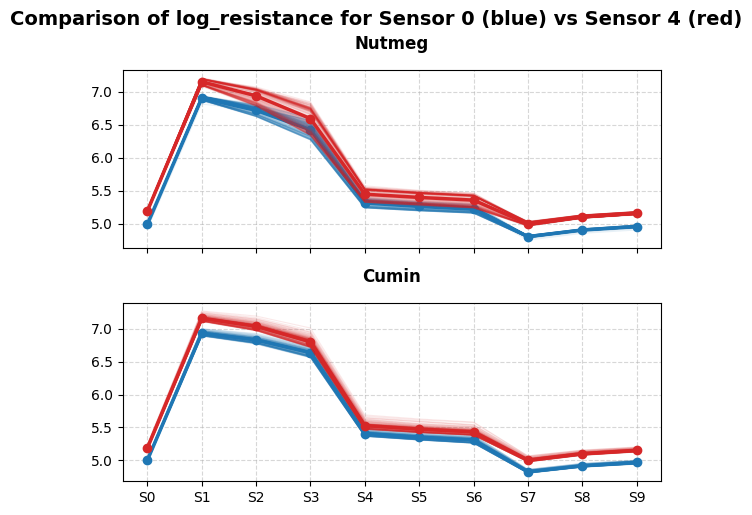

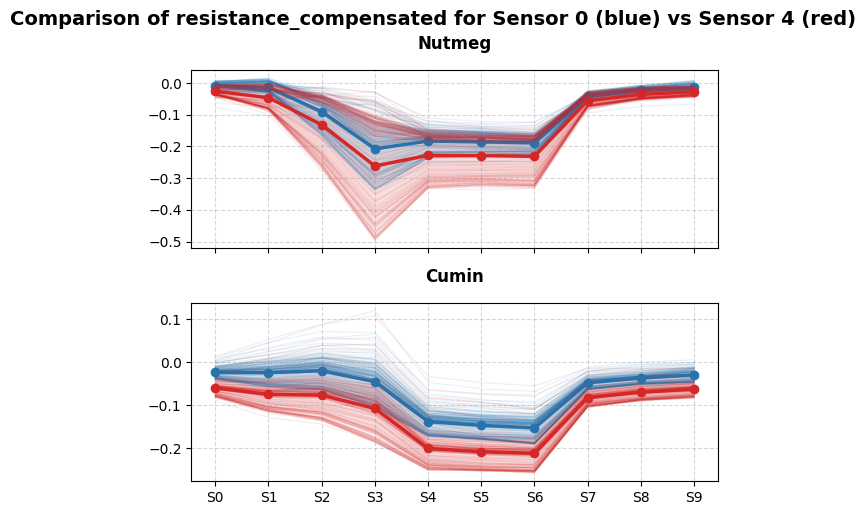

In [298]:
import matplotlib.pyplot as plt
import numpy as np

def plot_fingerprint_comparison(df, target_labels, target_feature):
    
    # Identify column groups
    feat_cols = [col for col in df.columns if col.startswith(target_feature)]
    steps = np.arange(10)

    fig, axes = plt.subplots(len(target_labels), 1, figsize=(6, 2.5*len(target_labels)), sharex=True)

    def draw_group(ax, data, label, color):
        # Filter for the specific gas/label
        mean = np.mean(data, axis=0)
        std = np.std(data, axis=0)

        # 1. Plot individual cycles with very high transparency
        for row in data:
            ax.plot(steps, row, color=color, alpha=0.1, linewidth=0.8)

        # 2. Plot shaded region (variance)
        ax.fill_between(steps, mean - std, mean + std, color=color, alpha=0.15, label='$\pm$1 Std Dev')

        # 3. Plot bold mean line (The "Fingerprint")
        ax.plot(steps, mean, color=color, linewidth=2.5, marker='o', markersize=6, label='Mean Fingerprint')

        ax.set_title(label, fontsize=12, fontweight='bold', pad=15)
        ax.grid(True, linestyle='--', alpha=0.5)
        # ax.legend(loc='upper right')
        ax.set_xticks(steps)
        ax.set_xticklabels([f'S{i}' for i in steps])

    for k, label in enumerate(target_labels):
        # Plot target 
        subset = df[(df['label_merged'] == label) & (df['sensor_index'] == K)]
        data = subset[feat_cols].values
        draw_group(axes[k], data, label, '#1f77b4')
    
        # Plot paired 
        subset = df[(df['label_merged'] == label) & (df['sensor_index'] == PAIR_K)]
        data = subset[feat_cols].values
        draw_group(axes[k], data, label, '#d62728')

    plt.tight_layout()
    plt.suptitle(f'Comparison of {target_feature} for Sensor {K} (blue) vs Sensor {PAIR_K} (red)', fontsize=14, fontweight='bold', y=1.02)
    plt.show()

plot_fingerprint_comparison(feature_matrix, ['Nutmeg', 'Cumin'], 'log_resistance')
plot_fingerprint_comparison(feature_matrix, ['Nutmeg', 'Cumin'], 'resistance_compensated')


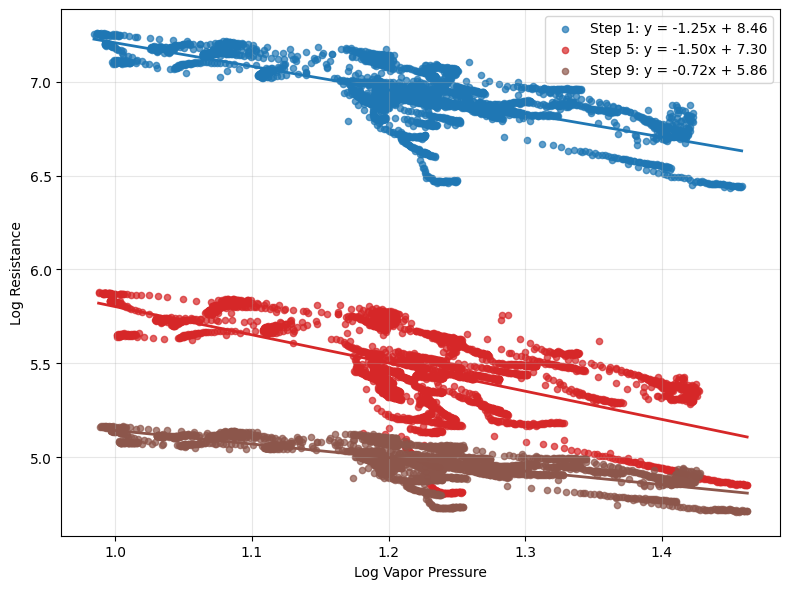

In [299]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RANSACRegressor

sensor_id = 0
step_ids = [1, 5, 9]
colors = ['C0', 'C3', 'C5']

fig, ax = plt.subplots(figsize=(8, 6))

for step_id, color in zip(step_ids, colors):
    subset = sensor_df[
        (sensor_df['sensor_index'] == sensor_id) &
        (sensor_df['heater_profile_step_index'] == step_id)
    ].copy().dropna(subset=['temperature', 'relative_humidity', 'log_resistance'])

    x = subset['log_vapor_pressure'].to_numpy().reshape(-1, 1)
    y = subset['log_resistance'].to_numpy().reshape(-1, 1)

    lr = LinearRegression()
    lr.fit(x, y)
    slope, intercept = lr.coef_[0][0], lr.intercept_[0]

    ax.scatter(x, y, alpha=0.7, s=20, color=color, label=f'Step {step_id}: y = {slope:.2f}x + {intercept:.2f}')

    x_fit = np.linspace(x.min(), x.max(), 200)
    ax.plot(x_fit, slope * x_fit + intercept, color=color, lw=2)

ax.set_xlabel('Log Vapor Pressure')
ax.set_ylabel('Log Resistance')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

,sensor_index,sensor_id,timestamp_since_poweron,real_time_clock,temperature,pressure,relative_humidity,resistance_gassensor,heater_profile_step_index,scanning_enabled,scanning_cycle_index,label_tag,error_code,label,class,source_file,label_merged,log_vapor_pressure,log_resistance
57892,0,880490094,1959573,0,37.797428,1015.287476,22.932501,506679.875000,6,1,1,2,0,Chestnuts,nuts,bme_690_data_17.csv,Chestnuts,1.205698,5.704735
57894,0,880490094,1960273,0,37.941166,1015.302795,22.797323,99263.281250,7,1,1,2,0,Chestnuts,nuts,bme_690_data_17.csv,Chestnuts,1.206472,4.996793
57895,0,880490094,1960973,0,38.036991,1015.276672,22.811674,115445.320312,8,1,1,1,0,Chestnuts,nuts,bme_690_data_17.csv,Chestnuts,1.208848,5.062380
57898,0,880490094,1961683,0,37.983753,1015.322876,22.520023,127426.578125,9,1,1,1,0,Chestnuts,nuts,bme_690_data_17.csv,Chestnuts,1.202430,5.105263
57902,0,880490094,1962528,0,37.917210,1015.307190,22.177914,136496.937500,0,1,1,1,0,Chestnuts,nuts,bme_690_data_17.csv,Chestnuts,1.194733,5.135126


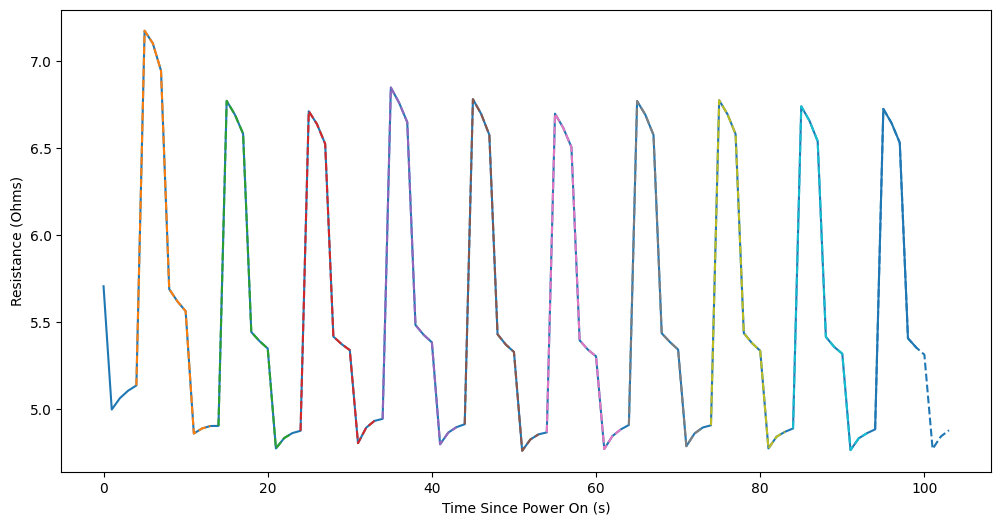

In [300]:
# Sanity check: compare the pivoted features to the original time series
target_feature = 'log_resistance'
plt.figure(figsize=(12, 6))
subset = sensor_df[(sensor_df['sensor_index'] == K) & (sensor_df['label_merged'] == LABEL)]
# Extract the first 100 data points
subset = subset.head(100)
plt.plot(np.arange(len(subset)),subset[target_feature], label=LABEL)

# overlay the pivoted data from the feature matrix for the same LABEL and sensor K
feature_subset = feature_matrix[(feature_matrix['sensor_index'] == K) & (feature_matrix['label_merged'] == LABEL)]
feat_cols = [col for col in feature_matrix.columns if col.startswith(target_feature)]
dat = feature_subset[feat_cols].values
rows, cols = dat.shape
for k in range(10):
    plt.plot(np.arange(cols) + k*cols + 4, dat[k, :], label=feat_cols[k], linestyle='--')

plt.xlabel('Time Since Power On (s)')
plt.ylabel('Resistance (Ohms)')
subset.head()

feature_cols=['log_resistance_0', 'log_resistance_1', 'log_resistance_2', 'log_resistance_3', 'log_resistance_4', 'log_resistance_5', 'log_resistance_6', 'log_resistance_7', 'log_resistance_8', 'log_resistance_9', 'log_vapor_pressure_0', 'log_vapor_pressure_1', 'log_vapor_pressure_2', 'log_vapor_pressure_3', 'log_vapor_pressure_4', 'log_vapor_pressure_5', 'log_vapor_pressure_6', 'log_vapor_pressure_7', 'log_vapor_pressure_8', 'log_vapor_pressure_9', 'diff_log_resistance_0', 'diff_log_resistance_1', 'diff_log_resistance_2', 'diff_log_resistance_3', 'diff_log_resistance_4', 'diff_log_resistance_5', 'diff_log_resistance_6', 'diff_log_resistance_7', 'diff_log_resistance_8', 'diff_log_resistance_9']


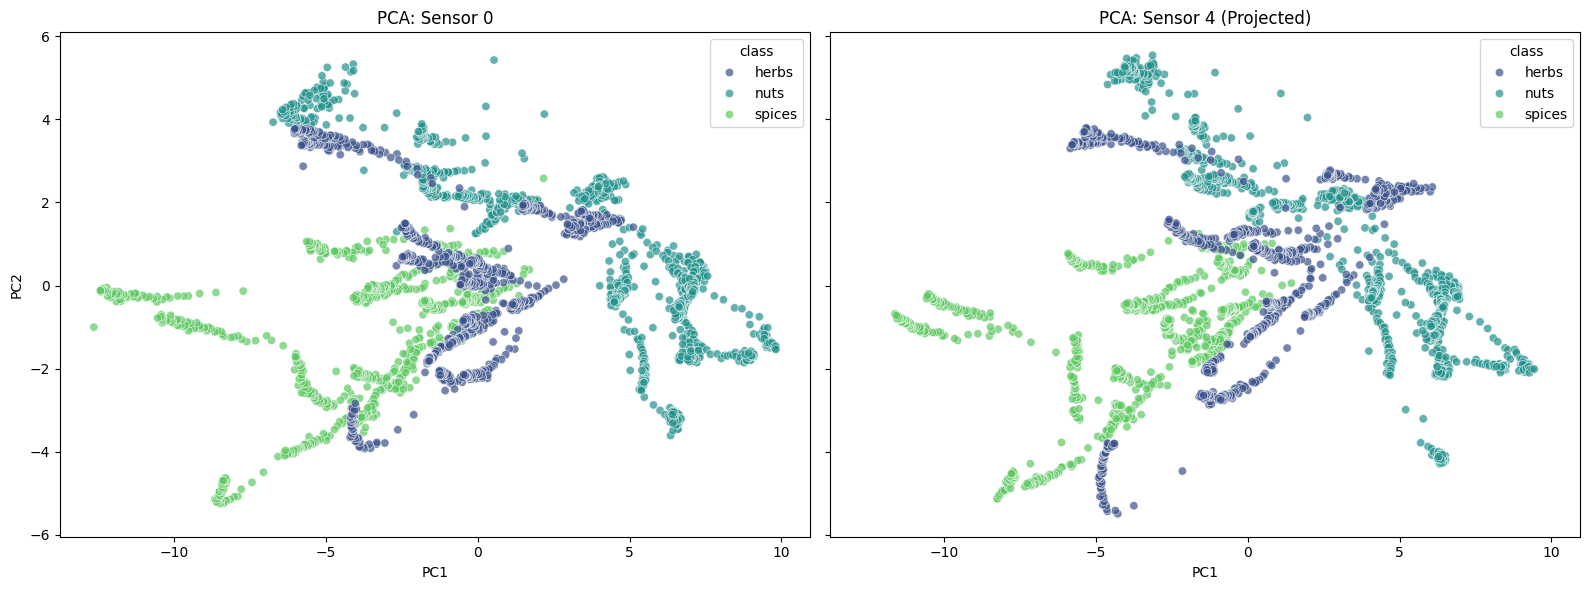

Total Variance Explained: 84.45%


In [301]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Separate the pair
df_k = feature_matrix[feature_matrix['sensor_index'] == K].copy()
df_pair = feature_matrix[feature_matrix['sensor_index'] == PAIR_K].copy()

# Feature Selection & Preprocessing
res_cols = [c for c in feature_matrix.columns if (FEATURE_LABEL in c or c.startswith('log_vapor_pressure'))]
# res_cols = [c for c in feature_matrix.columns if (c.startswith(FEATURE_LABEL) or c.startswith('log_vapor_pressure'))]
# res_cols = [c for c in feature_matrix.columns if FEATURE_LABEL in c]

feature_cols = res_cols
print(f"{feature_cols=}")

# Standardize and Fit PCA on Sensor K ONLY <= correlation instead of covariance may help scaling?
pca = PCA(n_components=2)


scale = True
if scale:
    scaler = StandardScaler()
    X_k_scaled = scaler.fit_transform(df_k[feature_cols])
    X_pair_scaled = scaler.fit_transform(df_pair[feature_cols])
else:
    X_k_scaled = df_k[feature_cols] 
    X_pair_scaled = df_pair[feature_cols]

y_k = df_k['label_merged']
y_pair = df_pair['label_merged']

pca.fit(X_k_scaled)

pca_k = pca.transform(X_k_scaled)

# Transform sensor K+4 using the SAME PCA model
pca_pair = pca.transform(X_pair_scaled)

# Visualization
# Get a unique list of label_mergeds and sort them alphabetically
# unique_labels = sorted(subset['label_merged'].unique())
unique_labels = sorted(feature_matrix['class'].unique())

# Create a consistent color palette map
# This assigns a specific color to each label_merged
palette = sns.color_palette("viridis", n_colors=len(unique_labels))
color_map = dict(zip(unique_labels, palette))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# Plot Sensor K with explicit hue_order
sns.scatterplot(
    data=df_k,
    x=pca_k[:, 0], y=pca_k[:, 1], 
    hue='class', 
    hue_order=unique_labels, # Ensures consistent color assignment
    palette=color_map, 
    ax=axes[0], 
    alpha=0.7
)
axes[0].set_title(f'PCA: Sensor {K}')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# Plot Sensor K+4 with the same hue_order and palette
sns.scatterplot(
    data=df_pair,
    x=pca_pair[:, 0], y=pca_pair[:, 1], 
    hue='class', 
    hue_order=unique_labels, # Critical for consistency
    palette=color_map, 
    ax=axes[1], 
    alpha=0.7
)
axes[1].set_title(f'PCA: Sensor {PAIR_K} (Projected)')
axes[1].set_xlabel('PC1')

plt.tight_layout()
plt.show()

# Print variance explained
print(f"Total Variance Explained: {np.sum(pca.explained_variance_ratio_)*100:.2f}%")

--- Results for Pair (0, 4) ---
Classification Accuracy on Sensor 4 using Sensor 0 model: 78.50%


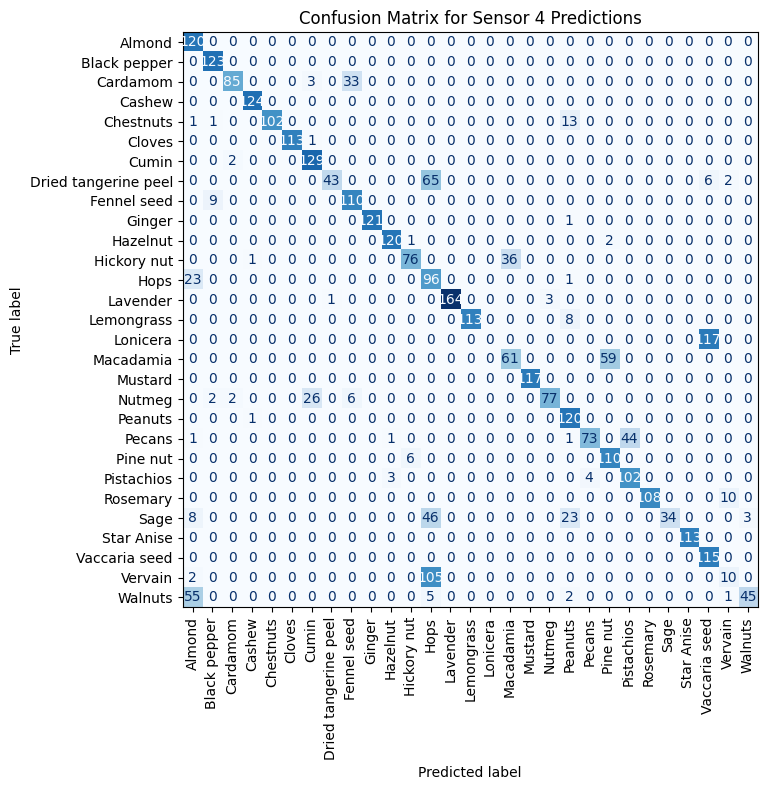

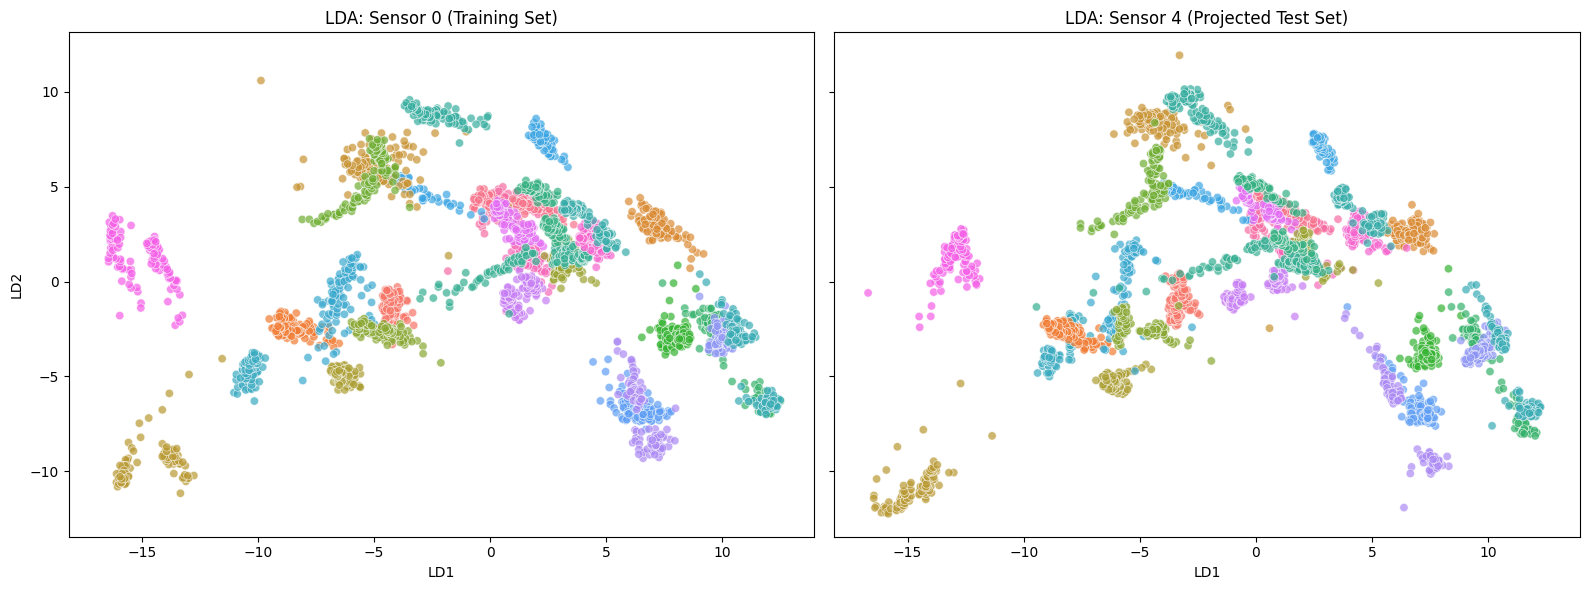

In [302]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
# Fit LDA on Sensor K
lda = LinearDiscriminantAnalysis(n_components=2) # We'll project to 2D for the plot
lda_k = lda.fit_transform(X_k_scaled, y_k)

# Project and Score Sensor K+4
# This uses the transformation weights learned from Sensor K
lda_pair = lda.transform(X_pair_scaled)
score_pair = lda.score(X_pair_scaled, y_pair)
print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")

unique_labels = sorted(feature_matrix['label_merged'].unique())
#unique_labels = sorted(feature_matrix['class'].unique())

# Confusion matrix
y_pred_pair = lda.predict(X_pair_scaled)
cm = confusion_matrix(y_pair, y_pred_pair, labels=unique_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_labels)
fig, ax = plt.subplots(figsize=(16, 8))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=90, colorbar=False)
ax.set_title(f'Confusion Matrix for Sensor {PAIR_K} Predictions')
fig.tight_layout()

# Visualization
palette = sns.color_palette("husl", n_colors=len(unique_labels))
color_map = dict(zip(unique_labels, palette))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# Plot Sensor K
sns.scatterplot(
    x=lda_k[:, 0], y=lda_k[:, 1], 
    hue=y_k, hue_order=unique_labels, palette=color_map,
    ax=axes[0], alpha=0.7
)
# remove legend
axes[0].legend_.remove()
axes[0].set_title(f'LDA: Sensor {K} (Training Set)')
axes[0].set_xlabel('LD1')
axes[0].set_ylabel('LD2')

# Plot Sensor K+4
sns.scatterplot(
    x=lda_pair[:, 0], y=lda_pair[:, 1], 
    hue=y_pair, hue_order=unique_labels, palette=color_map,
    ax=axes[1], alpha=0.7
)
axes[1].legend_.remove()
axes[1].set_title(f'LDA: Sensor {PAIR_K} (Projected Test Set)')
axes[1].set_xlabel('LD1')

plt.tight_layout()
plt.show()



In [303]:
from sklearn.ensemble import RandomForestClassifier
# Fit RandomForest on Sensor K
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_k = rf.fit(X_k_scaled, y_k)

# Project and Score Sensor K+4
# This uses the transformation weights learned from Sensor K
rf_pair = rf.predict(X_pair_scaled)
score_pair = rf.score(X_pair_scaled, y_pair)

print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")

--- Results for Pair (0, 4) ---
Classification Accuracy on Sensor 4 using Sensor 0 model: 76.25%


In [304]:
from sklearn import svm
clf = svm.SVC(kernel='linear')
clf.fit(X_k_scaled, y_k)
clf_pair = clf.predict(X_pair_scaled)
score_pair = clf.score(X_pair_scaled, y_pair)
print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")


--- Results for Pair (0, 4) ---
Classification Accuracy on Sensor 4 using Sensor 0 model: 78.01%


In [305]:
from sklearn.neural_network import MLPClassifier
clf = MLPClassifier(hidden_layer_sizes=(100,4), activation='relu', max_iter=5000)
clf.fit(X_k_scaled, y_k)
score_pair = clf.score(X_pair_scaled, y_pair)
print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")


--- Results for Pair (0, 4) ---
Classification Accuracy on Sensor 4 using Sensor 0 model: 55.07%


In [306]:
# KNN with cosine similarity
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_k_scaled, y_k)
score_pair = knn.score(X_pair_scaled, y_pair)
print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")

--- Results for Pair (0, 4) ---
Classification Accuracy on Sensor 4 using Sensor 0 model: 79.05%
